# 探索的データ解析 (EDA) - 加工前生データ (Raw Data)

本ノートブックは、実験計測アプリ（WebカメラによるMediaPipe顔ランドマークおよび顔ROI領域RGB輝度計測）から収集された**加工前生データ（Raw Data）**の特性を探索的に分析・可視化するためのものです。

### 主な分析観点:
1. **欠損値とサンプリングレートの確認:** 計測フレームの欠損（顔未検出）、サンプリングジッター、実効FPS、フレームドロップ（>100ms）の評価
2. **生波形の可視化とノイズの特定:** rPPG脈波（RGBチャネル）および顔ランドマーク（EAR・頭部姿勢）の生波形、高周波センサノイズ、体動アーチファクトの特定
3. **個人差（ベースラインのズレ）の確認:** 肌色・照明環境によるRGB輝度レベルの差、骨格や目の開き具合によるEARベースラインの個人差の可視化
4. **クラスバランスの確認:** 被験者別および全体での集中度ラベル（1: 集中, 0: 非集中）の分布・不均衡度の評価

> **拡張性:** `preprocess/data/raw/` ディレクトリ内の全被験者CSVを自動走査するため、今後被験者数やデータ数が増加してもそのまま動作します。


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import japanize_matplotlib
except ImportError:
    pass

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['IPAexGothic', 'Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

project_root = Path.cwd().parent.parent if Path.cwd().name == 'raw' else Path.cwd()
raw_dir = project_root / 'preprocess' / 'data' / 'raw'
report_fig_dir = project_root / 'eda' / 'raw' / 'reports' / 'figures'
report_fig_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root.resolve()}")
print(f"Raw data directory: {raw_dir.resolve()}")


Project root: /home/shigure/make_ai
Raw data directory: /home/shigure/make_ai/preprocess/data/raw


## 1. ヘルパー関数と被験者ファイルの自動走査
ディレクトリ内の全被験者CSV（マスターファイルを除く）を動的に検出します。


In [2]:
def scan_raw_files(data_dir: Path):
    files = sorted([f for f in data_dir.glob("*.csv") if f.name != "calibration_master.csv"])
    if not files:
        raise FileNotFoundError(f"No CSV files found in {data_dir}")
    return files

def calculate_ear_from_landmarks(df: pd.DataFrame) -> pd.Series:
    try:
        if 'lm_ear_386_y' in df.columns and 'lm_ear_374_y' in df.columns:
            h_left = np.sqrt((df['lm_ear_362_x'] - df['lm_ear_263_x'])**2 + (df['lm_ear_362_y'] - df['lm_ear_263_y'])**2)
            v_left1 = np.sqrt((df['lm_ear_385_x'] - df['lm_ear_373_x'])**2 + (df['lm_ear_385_y'] - df['lm_ear_373_y'])**2)
            v_left2 = np.sqrt((df['lm_ear_386_x'] - df['lm_ear_374_x'])**2 + (df['lm_ear_386_y'] - df['lm_ear_374_y'])**2)
            ear_left = (v_left1 + v_left2) / (2.0 * np.maximum(h_left, 1e-6))

            h_right = np.sqrt((df['lm_ear_33_x'] - df['lm_ear_133_x'])**2 + (df['lm_ear_33_y'] - df['lm_ear_133_y'])**2)
            v_right1 = np.sqrt((df['lm_ear_158_x'] - df['lm_ear_145_x'])**2 + (df['lm_ear_158_y'] - df['lm_ear_145_y'])**2)
            v_right2 = np.sqrt((df['lm_ear_159_x'] - df['lm_ear_144_x'])**2 + (df['lm_ear_159_y'] - df['lm_ear_144_y'])**2)
            ear_right = (v_right1 + v_right2) / (2.0 * np.maximum(h_right, 1e-6))
            return (ear_left + ear_right) / 2.0
    except Exception:
        pass
    return pd.Series(np.nan, index=df.index)

raw_files = scan_raw_files(raw_dir)
print(f"検出された被験者ファイル数: {len(raw_files)} 件")


検出された被験者ファイル数: 16 件


## 2. 全被験者サマリー集計 (欠損値・FPS・計測時間・クラス比率)
全被験者データを一括走査し、サンプリング品質と欠損率の統計量を算出します。


In [3]:
summaries = []
subject_dfs = {}

for f in raw_files:
    sub_id = f.stem
    df = pd.read_csv(f)
    n_rows = len(df)
    nan_rows = df.isnull().any(axis=1).sum()
    nan_cells = df.isnull().sum().sum()

    if 'clientPerfMs' in df.columns:
        dt_s = df['clientPerfMs'].diff().abs() / 1000.0
    else:
        dt_s = df['time'].diff().abs()
    
    dt_valid = dt_s[(dt_s > 0.001) & (dt_s < 2.0)]
    median_fps = (1.0 / dt_valid.median()) if len(dt_valid) > 0 and dt_valid.median() > 0 else np.nan
    std_dt = dt_valid.std() if len(dt_valid) > 0 else np.nan
    frame_drops = (dt_s > 0.1).sum()
    frame_drop_rate = (frame_drops / n_rows) * 100 if n_rows > 0 else 0

    l_counts = df['label'].value_counts().to_dict() if 'label' in df.columns else {}
    l0 = l_counts.get(0, 0)
    l1 = l_counts.get(1, 0)
    l1_rate = (l1 / (l0 + l1) * 100) if (l0 + l1) > 0 else 0
    duration_sec = (n_rows / median_fps) if not np.isnan(median_fps) and median_fps > 0 else 0

    summaries.append({
        'subject_id': sub_id,
        'total_rows': n_rows,
        'duration_sec': round(duration_sec, 1),
        'nan_rows': nan_rows,
        'nan_rate_pct': round((nan_rows / n_rows) * 100, 3) if n_rows > 0 else 0,
        'median_fps': round(median_fps, 2),
        'dt_std_ms': round(std_dt * 1000, 2) if not np.isnan(std_dt) else np.nan,
        'frame_drops_gt100ms': frame_drops,
        'frame_drop_rate_pct': round(frame_drop_rate, 2),
        'label_0_count': l0,
        'label_1_count': l1,
        'label_1_ratio_pct': round(l1_rate, 2),
    })
    subject_dfs[sub_id] = df

summary_df = pd.DataFrame(summaries)
summary_csv_path = project_root / 'eda' / 'raw' / 'reports' / 'raw_eda_summary.csv'
summary_df.to_csv(summary_csv_path, index=False)
display(summary_df)


,subject_id,total_rows,duration_sec,nan_rows,nan_rate_pct,median_fps,dt_std_ms,frame_drops_gt100ms,frame_drop_rate_pct,label_0_count,label_1_count,label_1_ratio_pct
0,1783067519588,8558,570.8,0,0.000,14.99,6.89,94,1.10,1762,6796,79.41
1,1783067552538,8343,556.5,0,0.000,14.99,13.59,409,4.90,1748,6595,79.05
2,74cOXS5nwF,11605,580.2,0,0.000,20.00,0.85,1,0.01,2415,9190,79.19
3,EPu3DMEDU3,8733,582.5,3,0.034,14.99,1.91,0,0.00,1814,6919,79.23
4,ESJdSRZW0Z,8583,572.5,0,0.000,14.99,5.98,67,0.78,1786,6797,79.19
5,G7YcccfktZ,11604,580.2,0,0.000,20.00,0.44,0,0.00,2417,9187,79.17
6,H6SaVKMe91,7672,512.5,5,0.065,14.97,30.14,1535,20.01,1131,6541,85.26
7,OIArwJxCJx,8706,580.7,0,0.000,14.99,0.62,1,0.01,1814,6892,79.16
8,bIZOWHQd39,8609,574.2,0,0.000,14.99,5.66,50,0.58,1752,6857,79.65
9,d2G3Tj0tfu,12533,557.7,0,0.000,22.47,7.03,0,0.00,2582,9951,79.40


## 3. 欠損値とサンプリングレートの確認
### 3.1 サンプリング間隔 (Δt) と実効FPSの分布


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


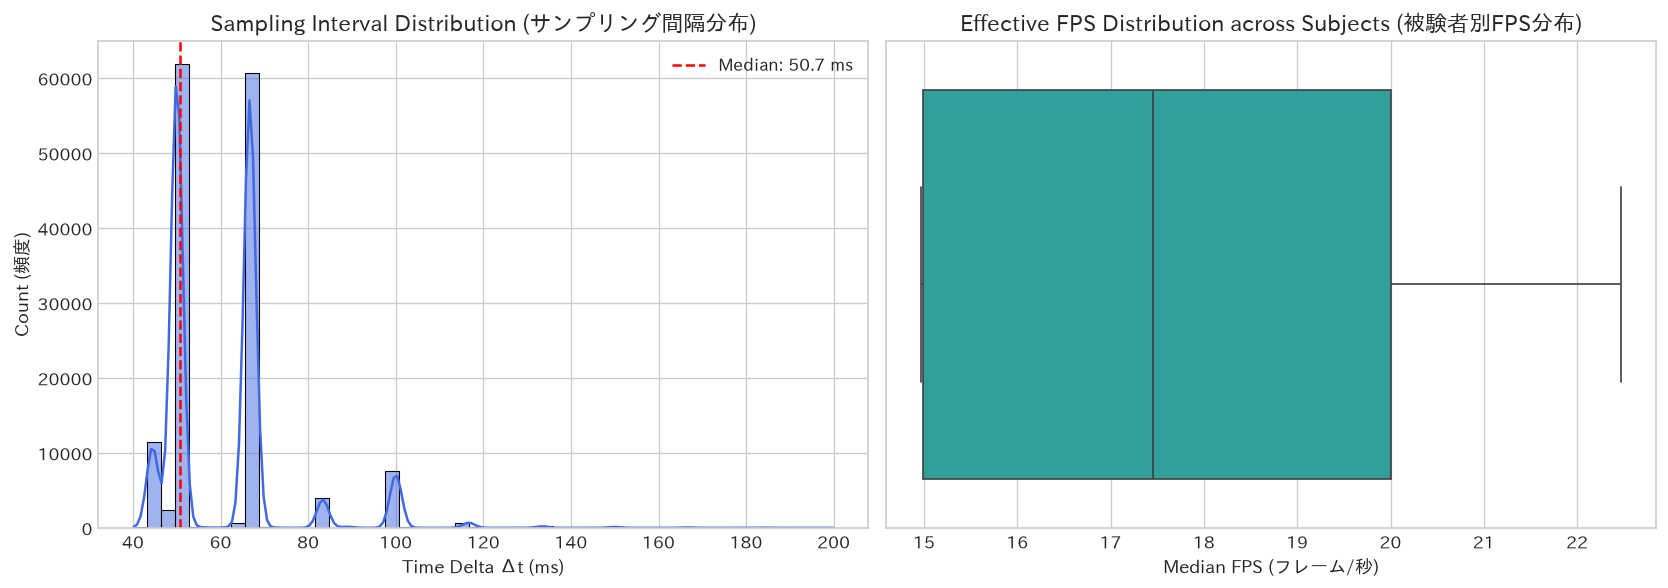

findfont: Failed to find font weight bold for IPAexGothic, now using 400.


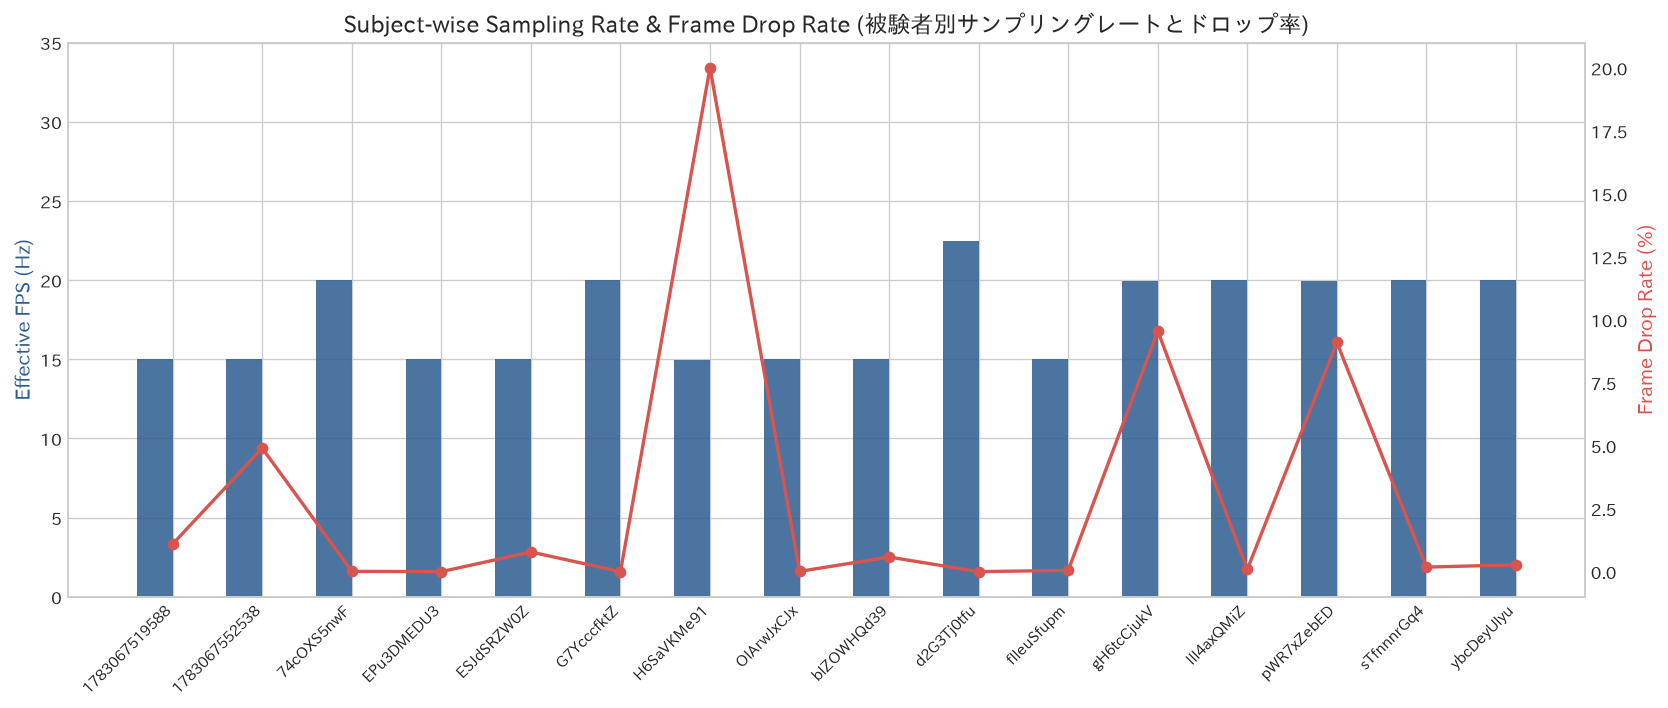

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
all_dts = []
for df in subject_dfs.values():
    if 'clientPerfMs' in df.columns:
        d = df['clientPerfMs'].diff().abs() / 1000.0
    else:
        d = df['time'].diff().abs()
    d_val = d[(d > 0.001) & (d < 0.2)]
    all_dts.extend(d_val.dropna().tolist())

all_dts = np.array(all_dts)

sns.histplot(all_dts * 1000, bins=50, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title("Sampling Interval Distribution (サンプリング間隔分布)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Time Delta Δt (ms)", fontsize=11)
axes[0].set_ylabel("Count (頻度)", fontsize=11)
axes[0].axvline(np.median(all_dts) * 1000, color='red', linestyle='--', label=f'Median: {np.median(all_dts)*1000:.1f} ms')
axes[0].legend()

sns.boxplot(x=summary_df['median_fps'], color='lightseagreen', ax=axes[1])
axes[1].set_title("Effective FPS Distribution across Subjects (被験者別FPS分布)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Median FPS (フレーム/秒)", fontsize=11)
plt.tight_layout()
plt.savefig(report_fig_dir / "fig1_sampling_rate_distribution.png", dpi=200)
plt.show()

fig, ax1 = plt.subplots(figsize=(14, 6))
x = np.arange(len(summary_df))
width = 0.4
ax1.bar(x - width/2, summary_df['median_fps'], width=width, label='Median FPS', color='#2b5c8f', alpha=0.85)
ax1.set_ylabel("Effective FPS (Hz)", fontsize=12, color='#2b5c8f')
ax1.set_xticks(x)
ax1.set_xticklabels(summary_df['subject_id'], rotation=45, ha='right', fontsize=9)
ax1.set_ylim(0, max(summary_df['median_fps'].max() * 1.25, 35))

ax2 = ax1.twinx()
ax2.plot(x, summary_df['frame_drop_rate_pct'], color='#d9534f', marker='o', linewidth=2, label='Frame Drop Rate (>100ms %)')
ax2.set_ylabel("Frame Drop Rate (%)", fontsize=12, color='#d9534f')
ax2.grid(False)

plt.title("Subject-wise Sampling Rate & Frame Drop Rate (被験者別サンプリングレートとドロップ率)", fontsize=14, fontweight='bold')
fig.tight_layout()
plt.savefig(report_fig_dir / "fig2_subject_fps_and_drops.png", dpi=200)
plt.show()


### 3.2 欠損値（NaN）の発生割合


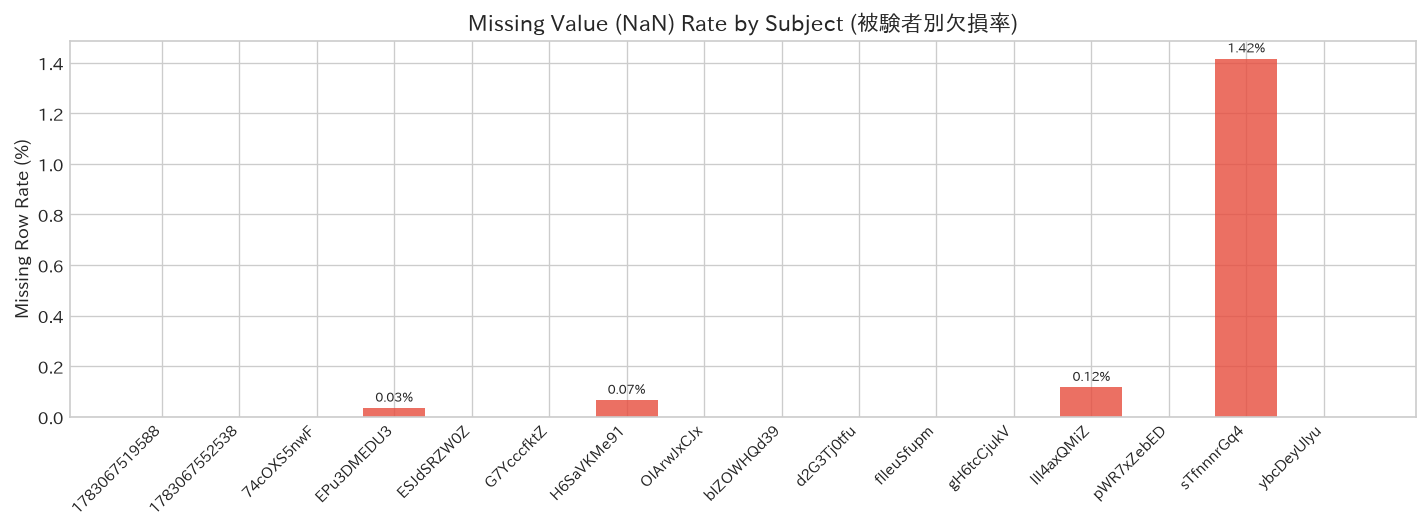

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar(summary_df['subject_id'], summary_df['nan_rate_pct'], color='#e74c3c', alpha=0.8)
ax.set_title("Missing Value (NaN) Rate by Subject (被験者別欠損率)", fontsize=13, fontweight='bold')
ax.set_ylabel("Missing Row Rate (%)", fontsize=11)
ax.set_xticks(range(len(summary_df)))
ax.set_xticklabels(summary_df['subject_id'], rotation=45, ha='right', fontsize=9)
for bar in bars:
    h = bar.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig(report_fig_dir / "fig3_missing_values_summary.png", dpi=200)
plt.show()


## 4. 生波形の可視化とノイズの特定
### 4.1 生rPPGシグナル（RGB輝度）とサンプリングジッター


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


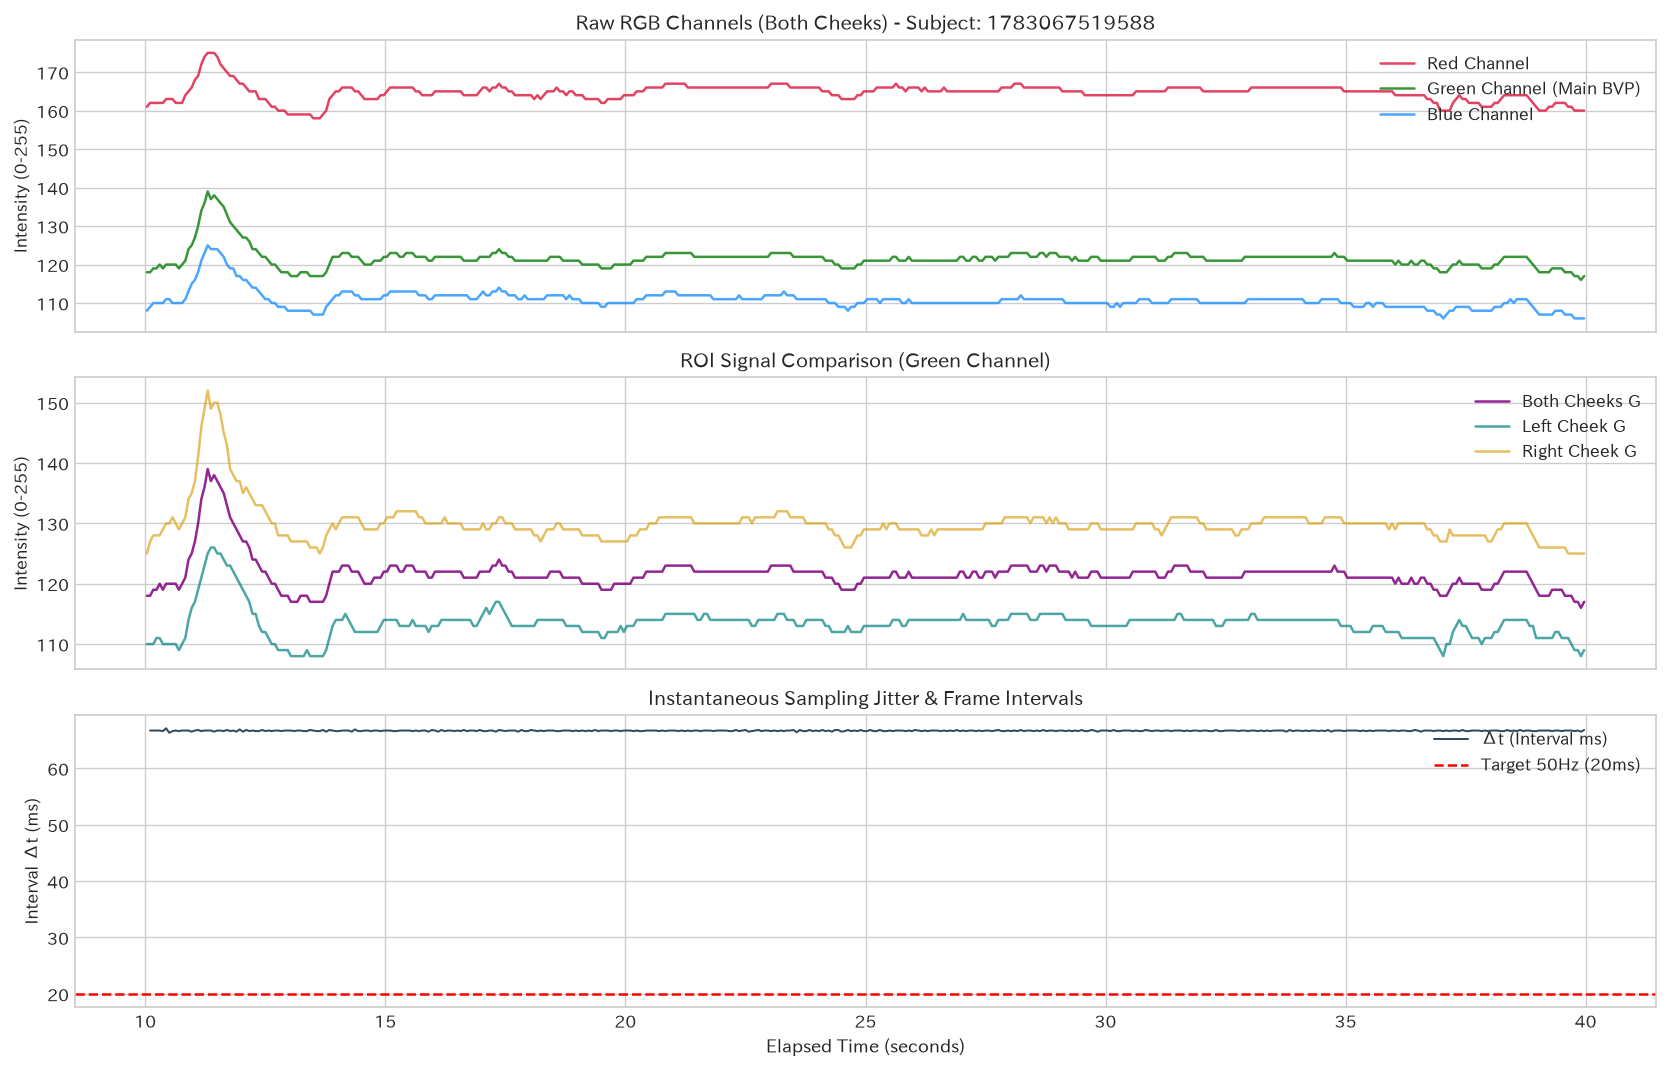

In [6]:
target_sub = summary_df.iloc[0]['subject_id']
sample_df = subject_dfs[target_sub].copy()

if 'clientPerfMs' in sample_df.columns:
    t_sec = (sample_df['clientPerfMs'] - sample_df['clientPerfMs'].iloc[0]) / 1000.0
else:
    t_sec = sample_df['time'] - sample_df['time'].iloc[0]

mask_window = (t_sec >= 10) & (t_sec <= 40)
if mask_window.sum() < 50:
    mask_window = slice(0, min(1500, len(sample_df)))
    t_sub = t_sec.iloc[mask_window]
else:
    t_sub = t_sec[mask_window]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
if 'rppg_bothCheeks_r' in sample_df.columns:
    axes[0].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_bothCheeks_r'], color='crimson', label='Red Channel', alpha=0.8)
    axes[0].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_bothCheeks_g'], color='forestgreen', label='Green Channel (Main BVP)', alpha=0.9)
    axes[0].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_bothCheeks_b'], color='dodgerblue', label='Blue Channel', alpha=0.8)
    axes[0].set_title(f"Raw RGB Channels (Both Cheeks) - Subject: {target_sub}", fontsize=12, fontweight='bold')
    axes[0].set_ylabel("Intensity (0-255)", fontsize=10)
    axes[0].legend(loc='upper right')

if 'rppg_bothCheeks_g' in sample_df.columns and 'rppg_leftCheek_g' in sample_df.columns:
    axes[1].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_bothCheeks_g'], color='purple', label='Both Cheeks G', alpha=0.85)
    axes[1].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_leftCheek_g'], color='teal', label='Left Cheek G', alpha=0.7)
    axes[1].plot(t_sub, sample_df.loc[t_sub.index, 'rppg_rightCheek_g'], color='goldenrod', label='Right Cheek G', alpha=0.7)
    axes[1].set_title("ROI Signal Comparison (Green Channel)", fontsize=12, fontweight='bold')
    axes[1].set_ylabel("Intensity (0-255)", fontsize=10)
    axes[1].legend(loc='upper right')

dt_sub = t_sub.diff() * 1000
axes[2].plot(t_sub, dt_sub, color='#34495e', linewidth=1.2, label='Δt (Interval ms)')
axes[2].axhline(20, color='red', linestyle='--', label='Target 50Hz (20ms)')
axes[2].set_title("Instantaneous Sampling Jitter & Frame Intervals", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Elapsed Time (seconds)", fontsize=11)
axes[2].set_ylabel("Interval Δt (ms)", fontsize=10)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.savefig(report_fig_dir / "fig4_raw_rppg_signals_noise.png", dpi=200)
plt.show()


### 4.2 生ランドマーク波形 (EAR・頭部姿勢)


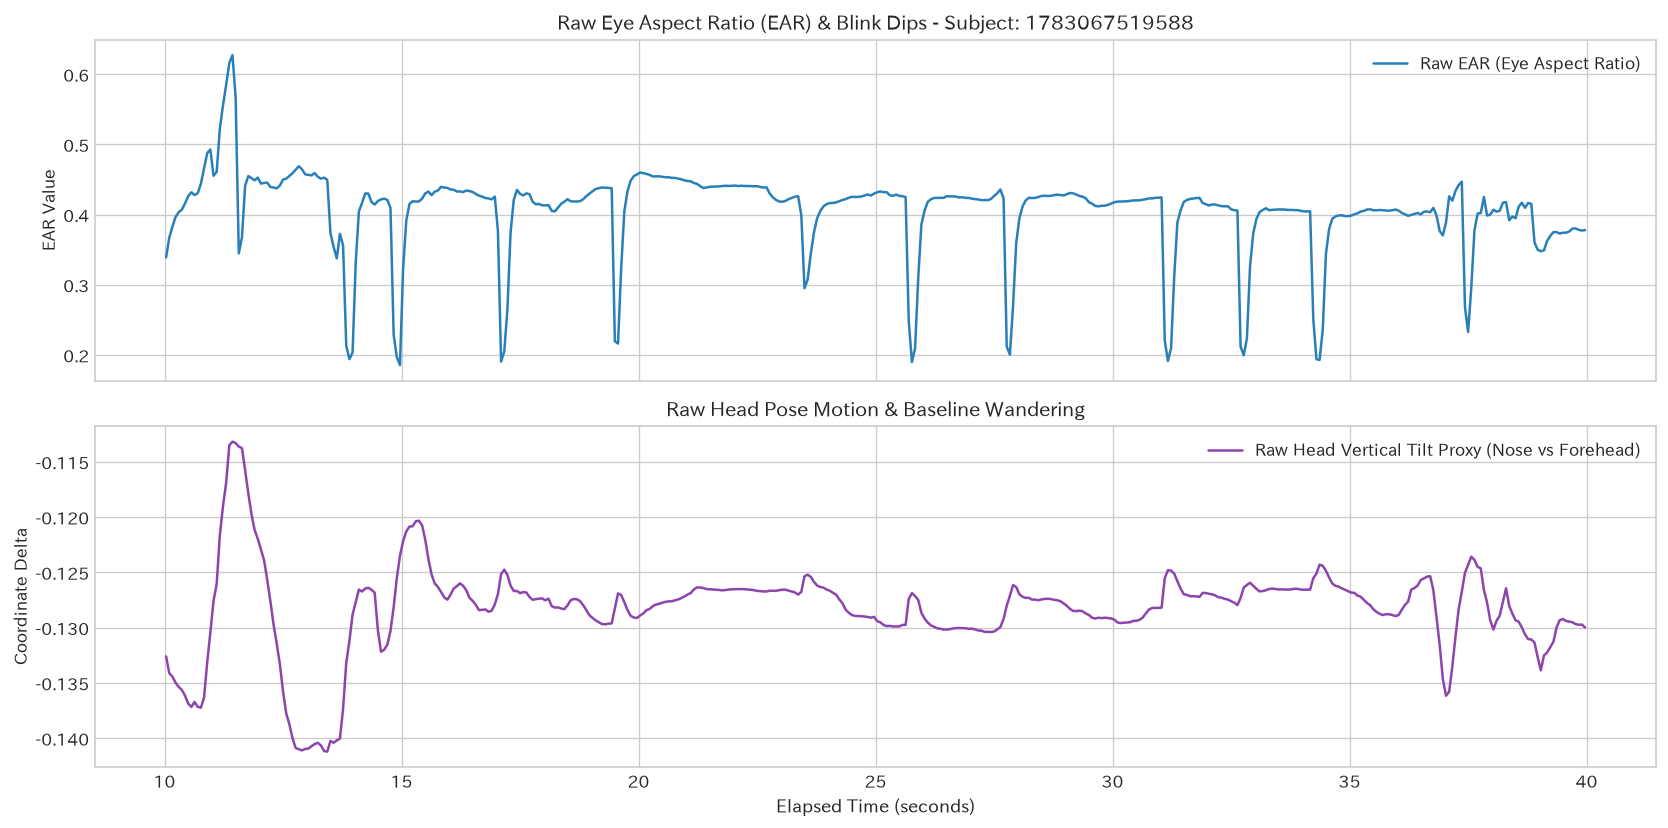

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ear_sub = calculate_ear_from_landmarks(sample_df).loc[t_sub.index]
axes[0].plot(t_sub, ear_sub, color='#2980b9', linewidth=1.5, label='Raw EAR (Eye Aspect Ratio)')
axes[0].set_title(f"Raw Eye Aspect Ratio (EAR) & Blink Dips - Subject: {target_sub}", fontsize=12, fontweight='bold')
axes[0].set_ylabel("EAR Value", fontsize=10)
axes[0].legend(loc='upper right')

if 'lm_headPose_4_y' in sample_df.columns and 'lm_headPose_10_y' in sample_df.columns:
    head_tilt = sample_df.loc[t_sub.index, 'lm_headPose_10_y'] - sample_df.loc[t_sub.index, 'lm_headPose_4_y']
    axes[1].plot(t_sub, head_tilt, color='#8e44ad', linewidth=1.5, label='Raw Head Vertical Tilt Proxy (Nose vs Forehead)')
    axes[1].set_title("Raw Head Pose Motion & Baseline Wandering", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Elapsed Time (seconds)", fontsize=11)
    axes[1].set_ylabel("Coordinate Delta", fontsize=10)
    axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(report_fig_dir / "fig5_raw_landmarks_ear_pose.png", dpi=200)
plt.show()


## 5. 個人差（ベースラインのズレ）の確認


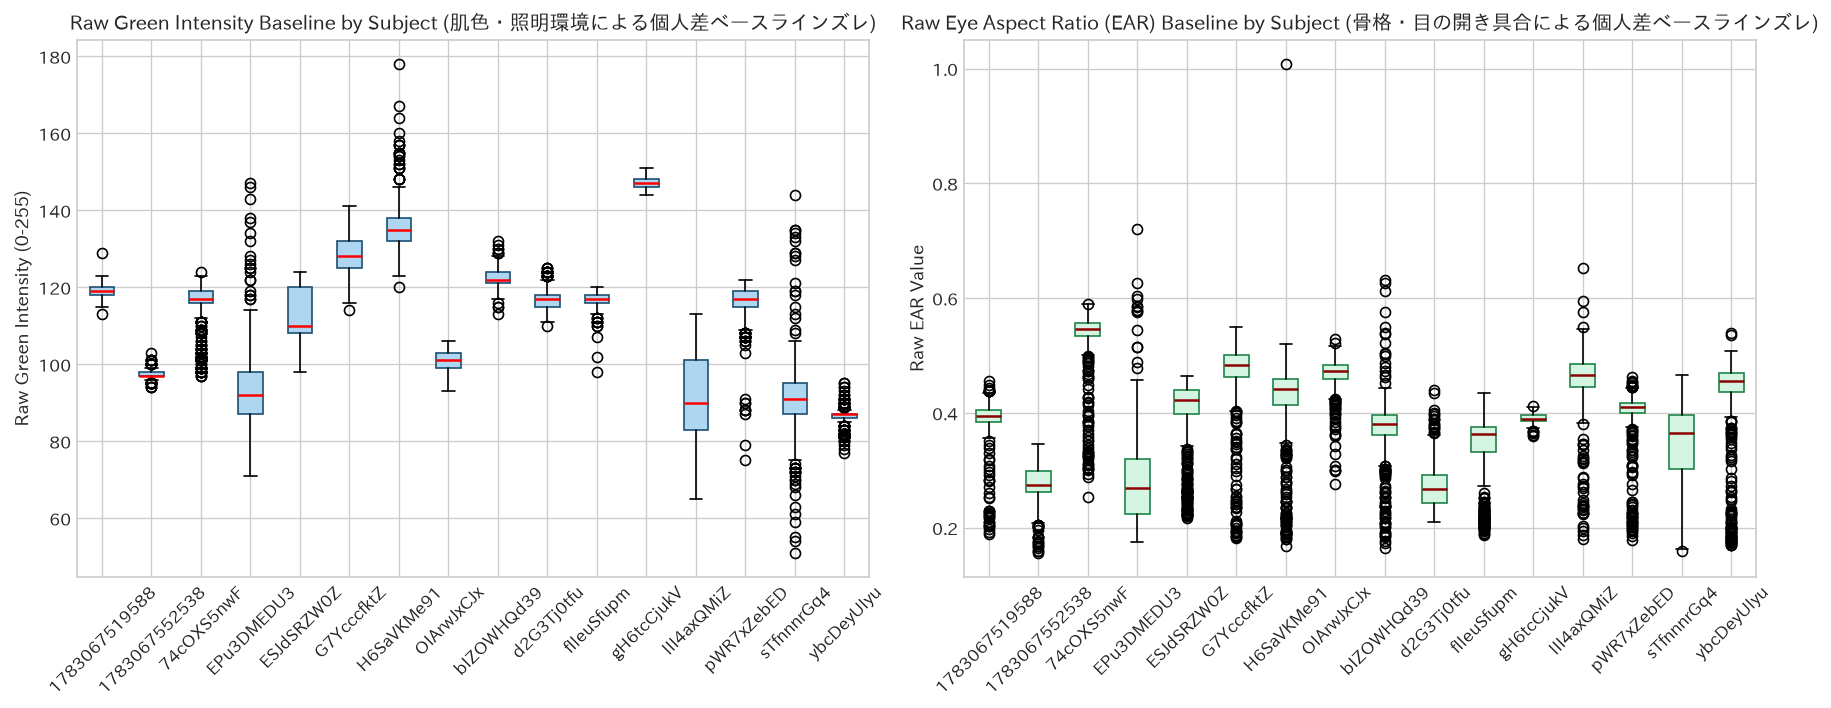

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rppg_data = []
labels_list = []
for sub_id, df in subject_dfs.items():
    if 'rppg_bothCheeks_g' in df.columns:
        vals = df['rppg_bothCheeks_g'].dropna()
        if len(vals) > 500: vals = vals.sample(500, random_state=42)
        rppg_data.append(vals)
        labels_list.append(sub_id)

axes[0].boxplot(rppg_data, tick_labels=labels_list, patch_artist=True,
                boxprops=dict(facecolor='#aed6f1', color='#1b4f72'),
                medianprops=dict(color='red', linewidth=1.5))
axes[0].set_title("Raw Green Intensity Baseline by Subject (肌色・照明環境による個人差ベースラインズレ)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Raw Green Intensity (0-255)", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

ear_data = []
ear_labels = []
for sub_id, df in subject_dfs.items():
    e = calculate_ear_from_landmarks(df).dropna()
    if len(e) > 500: e = e.sample(500, random_state=42)
    if len(e) > 0:
        ear_data.append(e)
        ear_labels.append(sub_id)

axes[1].boxplot(ear_data, tick_labels=ear_labels, patch_artist=True,
                boxprops=dict(facecolor='#d5f5e3', color='#1e8449'),
                medianprops=dict(color='darkred', linewidth=1.5))
axes[1].set_title("Raw Eye Aspect Ratio (EAR) Baseline by Subject (骨格・目の開き具合による個人差ベースラインズレ)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Raw EAR Value", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(report_fig_dir / "fig6_individual_baseline_differences.png", dpi=200)
plt.show()


## 6. クラスバランスの確認


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


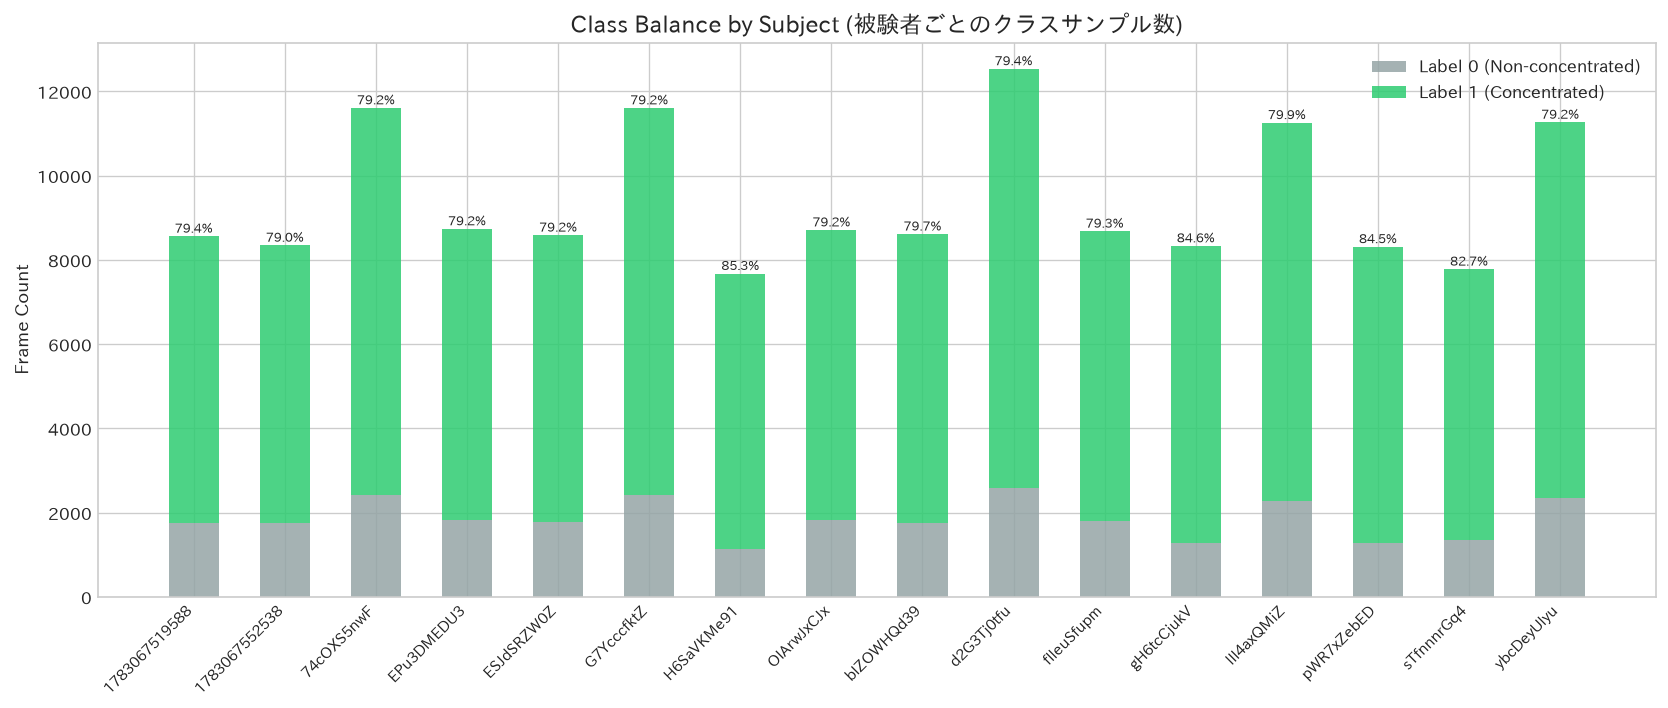

findfont: Failed to find font weight bold for IPAexGothic, now using 400.


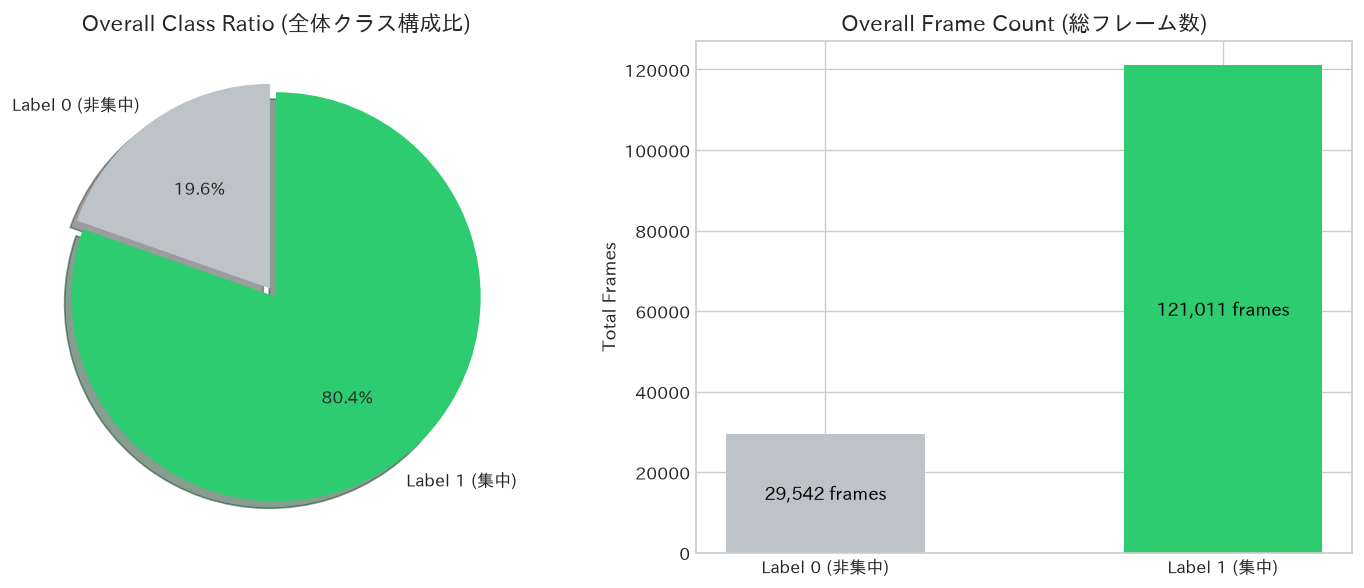

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(summary_df))
width = 0.55
ax.bar(x, summary_df['label_0_count'], width, label='Label 0 (Non-concentrated)', color='#95a5a6', alpha=0.85)
ax.bar(x, summary_df['label_1_count'], width, bottom=summary_df['label_0_count'],
       label='Label 1 (Concentrated)', color='#2ecc71', alpha=0.85)

ax.set_title("Class Balance by Subject (被験者ごとのクラスサンプル数)", fontsize=14, fontweight='bold')
ax.set_ylabel("Frame Count", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(summary_df['subject_id'], rotation=45, ha='right', fontsize=9)
ax.legend(loc='upper right')

for i, (tot, r) in enumerate(zip(summary_df['label_0_count'] + summary_df['label_1_count'], summary_df['label_1_ratio_pct'])):
    ax.text(i, tot + 50, f"{r:.1f}%", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(report_fig_dir / "fig7_class_balance_by_subject.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
total_l0 = summary_df['label_0_count'].sum()
total_l1 = summary_df['label_1_count'].sum()

axes[0].pie([total_l0, total_l1], labels=['Label 0 (非集中)', 'Label 1 (集中)'],
            autopct='%1.1f%%', startangle=90, colors=['#bdc3c7', '#2ecc71'],
            explode=(0.05, 0), shadow=True)
axes[0].set_title("Overall Class Ratio (全体クラス構成比)", fontsize=13, fontweight='bold')

axes[1].bar(['Label 0 (非集中)', 'Label 1 (集中)'], [total_l0, total_l1], color=['#bdc3c7', '#2ecc71'], width=0.5)
axes[1].set_title("Overall Frame Count (総フレーム数)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Total Frames", fontsize=11)
for i, v in enumerate([total_l0, total_l1]):
    axes[1].text(i, v / 2, f"{v:,} frames", ha='center', va='center', color='black', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig(report_fig_dir / "fig8_class_balance_overall.png", dpi=200)
plt.show()


## 7. まとめと前処理パイプラインへの示唆

### 主要な分析結果:
1. **サンプリング間隔の不均一性とジッター:** 実効サンプリングレートは約15Hz〜20Hzであり、フレーム間隔 $\Delta t$ にばらつきが存在。➔ `preprocess` 工程での **50Hz PCHIP 補間リサンプリング** が不可欠。
2. **生波形とノイズ:** 生RGB輝度値には照明変動や体動による巨大なベースラインドリフトが含まれ、瞬目や首振りによるノイズが混在。➔ POSアルゴリズムによる色空間投影とバンドパスフィルタ（0.75〜2.5Hz）、Savitzky-Golay平滑化が有効に機能。
3. **被験者間のベースライン差異:** 肌色や骨格の違いにより、Raw特徴量の絶対水準が被験者ごとに大きく乖離。➔ 初期注視キャリブレーション（比率 `ear_ratio`、差分 `head_*_diff`）および個人内 Zスコア標準化により個人差を除去。
4. **クラス不均衡 (約8:2):** 集中状態（Label 1）が約79%、非集中状態（Label 0）が約21%。➔ LOSO-CV評価時およびモデル損失関数の重み付け設定（Class weights等）での配慮が必要。
